This notebook builds on the perceptual decision making task, and

1. partitions the neurons according to their selectivity index to stimulus 1&2
2. explores the modularity of the RNN
3. draws the psychometric curve of the RNN and compares the noise-robustness of EI-Sep RNN and simple RNN.


In [1]:
import numpy as np
import torch
import torch.nn as nn

import neurogym as ngym

import warnings
from IPython.display import clear_output
from torch.nn import functional as F
from matplotlib import pyplot as plt
from net.common import init_model
clear_output()
warnings.filterwarnings('ignore')
# from pdm_model import EISepLSTM, Net
# from pdm_model import load_model


In [2]:
# Environment
task = 'PerceptualDecisionMaking-v0'
kwargs = {'dt': 100}
seq_len = 100

# Make supervised dataset
dataset = ngym.Dataset(task, env_kwargs=kwargs, batch_size=16,
                       seq_len=seq_len)
env = dataset.env
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n

In [4]:
device = 'cuda'
def load_model(prefix: str, num_h: int, ob_size: int, act_size: int, device: str = "cpu") -> nn.Module:
    """Load a model from a file."""
    # if "simple" in prefix:
    #     model = init_model(ob_size, num_h, act_size, 'simple').to(device)
    # else:
    #     model = init_model(ob_size, num_h, act_size, 'eisep').to(device)
    #     model.set_temperature(-1)
    model = init_model(ob_size, num_h, act_size, 'ccstr_simple').to(device)
    model.load_state_dict(torch.load(f"./model/perceptualdecisionmaking/{prefix}.pth", map_location=device))
    model.eval()

    return model
# model = load_model('softplusact_relutraining_entropy1', num_h=64, ob_size=ob_size, act_size=act_size, device=device)
model = load_model('ccstr_simple', num_h=64, ob_size=ob_size, act_size=act_size, device=device)

Using Ccstr_SimpleNet
Using Ccstr_simpleRNN


In [4]:
weight = model.lstm.Wrec_free
corrected_weight = model.lstm.rec_filter(weight).detach().cpu().numpy()  # Apply the rectifier
# mask = F.gumbel_softmax(model.lstm.eimask_logit, tau=0.1, hard=False, dim=-1)
eimask_logit = model.lstm.eimask_logit.detach().cpu().numpy()
ei_code = np.where(eimask_logit[:, 0] > eimask_logit[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1) > 0, np.array([[1,0]]).repeat(eimask_logit.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask_logit.shape[0], axis=0))
actual_weight = corrected_weight @ np.diag(ei_code)  # Apply the mask to the weight


In [5]:
# print((np.abs(actual_weight) > 0.1).mean())
# weight = model.lstm.Wrec_free.detach().cpu().numpy()
weight = model.get_actual_weight().detach().cpu().numpy()
print(1-(np.abs(weight) > 0.1*np.std(np.abs(weight))).mean())

0.699462890625


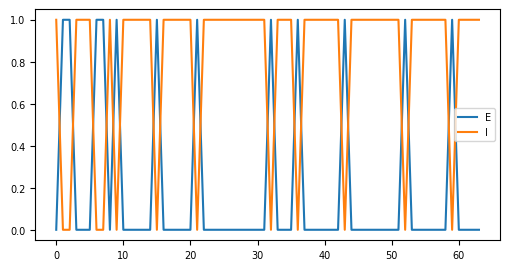

In [6]:
plt.figure(figsize=(6,3))
plt.plot(mask[:, 0], label='E')
plt.plot(mask[:, 1], label='I')
plt.legend()
plt.show()

In [7]:
print(model.lstm.eimask_logit)

Parameter containing:
tensor([[-3.7156,  4.1183],
        [ 4.0307, -3.9962],
        [ 3.9815, -4.1825],
        [-3.7864,  3.8649],
        [-3.9775,  3.8637],
        [-4.1675,  4.0010],
        [ 4.0971, -4.4113],
        [ 3.8437, -3.9617],
        [-4.0745,  3.7340],
        [ 3.9559, -4.0525],
        [-3.9172,  3.7716],
        [-3.9631,  3.8834],
        [-4.0469,  3.9459],
        [-3.6321,  4.1356],
        [-4.0386,  4.0149],
        [ 4.1631, -4.1522],
        [-3.8789,  3.8848],
        [-3.7467,  3.9575],
        [-4.0059,  4.0208],
        [-4.0583,  3.9018],
        [-3.8652,  4.1352],
        [ 4.0593, -3.9503],
        [-3.8752,  4.1128],
        [-4.0350,  4.1921],
        [-4.1224,  3.8815],
        [-3.7691,  3.9464],
        [-3.8894,  3.7055],
        [-3.9281,  3.8518],
        [-3.8979,  3.8814],
        [-4.1744,  4.0233],
        [-4.2190,  3.9354],
        [-3.9209,  3.9492],
        [ 3.9791, -3.9672],
        [-3.7276,  3.8642],
        [-3.8953,  3.9789]

In [6]:
perf = 0
num_trial = 2000
input_all = []
label_all = []
action_all = []
hidden_all = []
for i in range(num_trial):
    env.new_trial()
    ob, gt = env.ob, env.gt
    ob = ob[:, np.newaxis, :]  # Add batch axis
    inputs = torch.from_numpy(ob).type(torch.float).to(device)

    outputs, eimask_logit, hidden = model(inputs)
    action_pred = outputs.cpu().detach().numpy()
    action_pred = np.argmax(action_pred, axis=-1)
    perf += gt[-1] == action_pred[-1, 0]
    action_all.append(action_pred[-1, 0])
    input_all.append(ob[:,0,:])
    label_all.append(gt[-1])
    hidden_all.append(hidden[0][:,0].cpu().detach().numpy())

perf /= num_trial

In [7]:
print(f'Performance: {perf*100:.1f}%')

Performance: 88.9%


In [8]:
input_ar1 = np.array(input_all)
label_ar1 = np.array(label_all)
action_ar1 = np.array(action_all)
hidden_ar1 = np.array(hidden_all)

(2000, 22, 3) (2000,) (2000,) (2000, 22, 64)


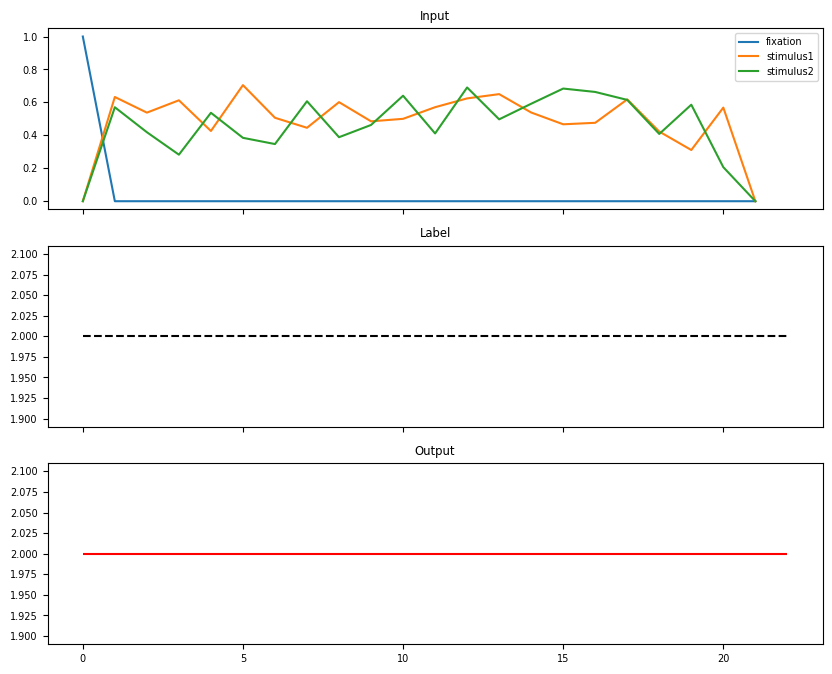

In [9]:
print(input_ar1.shape, label_ar1.shape, action_ar1.shape, hidden_ar1.shape)
fig, ax = plt.subplots(3,1, figsize=(10, 8), sharex=True)
ax[0].plot(input_ar1[1,:,0], label='fixation')
ax[0].plot(input_ar1[1,:,1], label='stimulus1')
ax[0].plot(input_ar1[1,:,2], label='stimulus2')
ax[0].set_title('Input')
ax[0].legend()
ax[1].hlines(label_ar1[0], 0, input_ar1.shape[1], color='black', linestyle='--')
ax[1].set_title('Label')
ax[2].hlines(action_ar1[0], 0, input_ar1.shape[1], color='red', label='predicted action')
ax[2].set_title('Output')
plt.show()

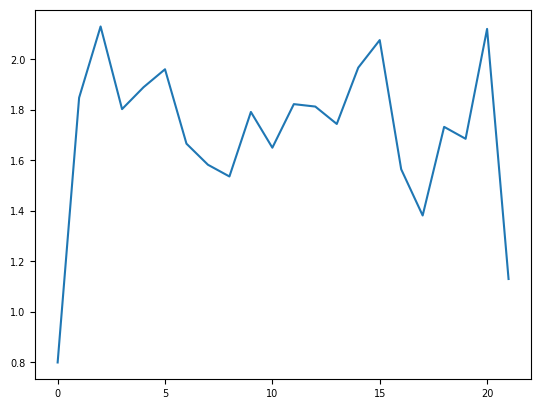

In [10]:
plt.plot(hidden_ar1[0,:,5])

In [11]:
print(hidden_ar1.mean())
print(hidden_ar1.std())

0.7234427
1.1612692


In [12]:
print((hidden_ar1>0).mean())

1.0


Analyze the most responding neurons to each stimuli


(877, 22, 64)
(1123, 22, 64)
[0.8154298  0.07700963 0.08126986 0.10450036 0.1901054  0.58480906
 0.10676245 0.12331421 0.25031868 0.16373351 1.0949097  0.20183663
 0.14045082 0.44977847 0.1122431  0.13065444 0.12946822 0.13708527
 0.07722197 1.9788343  0.09896313 0.22341962 0.09159653 1.1471515
 0.55481297 0.10116569 0.6645336  0.25288072 0.21661821 0.1342106
 0.2054651  0.15582311 0.10960154 0.1683027  0.14712094 0.2584467
 0.23398547 0.08159927 1.2255446  0.53381455 0.19284393 0.12325998
 0.1267828  0.23463741 0.11080522 0.12565875 0.66128534 0.19947284
 0.17761292 0.3219736  0.11578776 0.42750928 0.11853969 1.7933042
 0.17283256 1.4983436  0.2778866  0.26390985 1.0858526  0.07857984
 0.15800418 0.1817954  0.30940136 0.22013685]


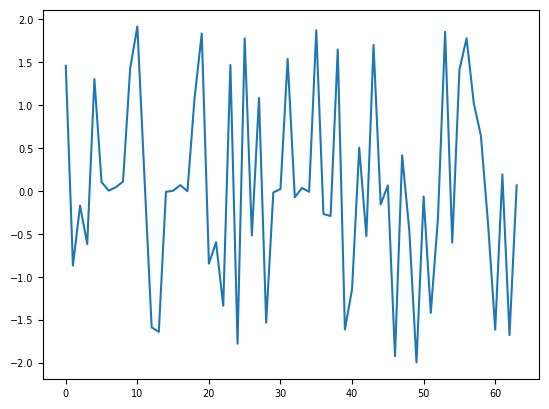

In [13]:
choice_1_ar = hidden_ar1[np.where(action_ar1 == 1)[0]]
print(choice_1_ar.shape)
choice_1_mean = choice_1_ar.mean(axis=(0,1))
choice_1_std = choice_1_ar.std(axis=(0,1))
choice_2_ar = hidden_ar1[np.where(action_ar1 == 2)[0]]
print(choice_2_ar.shape)
choice_2_mean = choice_2_ar.mean(axis=(0,1))
choice_2_std = choice_2_ar.std(axis=(0,1))
selectivity_index = (choice_1_mean - choice_2_mean)/(np.sqrt((choice_1_std**2 + choice_2_std**2)/2)+ 1e-8)
print(choice_1_std)
plt.plot(selectivity_index, label='selectivity index')

(64, 64)
(23,)
(26,)


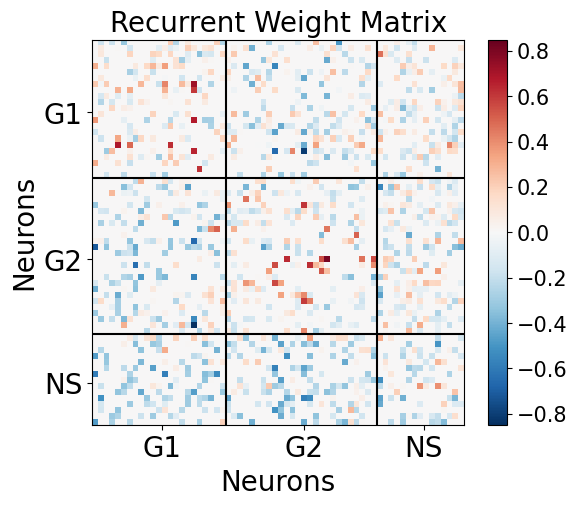

In [14]:
actual_weight = model.get_actual_weight().detach().cpu().numpy()
# actual_weight = model.lstm.Wrec.cpu().detach().numpy()
fontsize = 20


print(actual_weight.shape)
choice_1_neuron = np.where(selectivity_index > .1*np.std(selectivity_index))[0]
print(choice_1_neuron.shape)
choice_2_neuron = np.where(selectivity_index < -.1*np.std(selectivity_index))[0]
print(choice_2_neuron.shape)
# rearrange the weight matrix so that the neurons with the same selectivity index are together
N = actual_weight.shape[0]
all_neurons = np.arange(N)
other_neuron = np.setdiff1d(all_neurons,
                            np.concatenate((choice_1_neuron, choice_2_neuron)))

# 构造新的排列顺序：1 → 2 → 其他
perm = np.concatenate((choice_1_neuron, choice_2_neuron, other_neuron))

# 用 np.ix_ 同时重排行和列
reordered_weight = actual_weight[np.ix_(perm, perm)]
plt.figure(figsize=(6, 5))
limit = np.max(np.abs(reordered_weight))
plt.imshow(reordered_weight, cmap='RdBu_r', aspect='auto', vmin=-limit, vmax=limit)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=fontsize-5)

n_neuron1 = choice_1_neuron.shape[0]
n_neuron2 = choice_2_neuron.shape[0]
n_neuron_other = other_neuron.shape[0]
plt.vlines([n_neuron1 - 0.5, n_neuron1 + n_neuron2 - 0.5], -0.5, N-0.5, color='black', linestyle='-')
plt.hlines([n_neuron1 - 0.5, n_neuron1 + n_neuron2 - 0.5], -0.5, N-0.5, color='black', linestyle='-')

plt.xticks([n_neuron1/2, n_neuron1 + n_neuron2/2, n_neuron1 + n_neuron2 + n_neuron_other/2],
           ['G1', 'G2', 'NS'], fontsize=fontsize)
plt.yticks([n_neuron1/2, n_neuron1 + n_neuron2/2, n_neuron1 + n_neuron2 + n_neuron_other/2],
           ['G1', 'G2', 'NS'], fontsize=fontsize)
plt.title('Recurrent Weight Matrix', fontsize=fontsize)
plt.xlabel('Neurons', fontsize=fontsize)
plt.ylabel('Neurons', fontsize=fontsize)
# plt.show()
plt.savefig('./output/pdm_recurrent_weight_matrix.png', dpi=400)

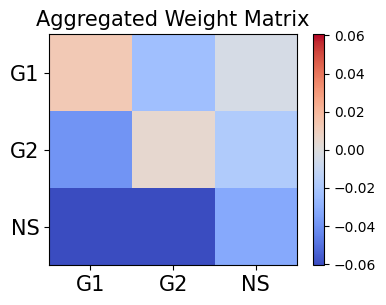

In [15]:
fontsize=15
group_weight = np.zeros((3,3))
group_weight[0,0] = reordered_weight[:n_neuron1, :n_neuron1].mean()
group_weight[0,1] = reordered_weight[:n_neuron1, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight[0,2] = reordered_weight[:n_neuron1, n_neuron1+n_neuron2:].mean()
group_weight[1,0] = reordered_weight[n_neuron1:n_neuron1+n_neuron2, :n_neuron1].mean()
group_weight[1,1] = reordered_weight[n_neuron1:n_neuron1+n_neuron2, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight[1,2] = reordered_weight[n_neuron1:n_neuron1+n_neuron2, n_neuron1+n_neuron2:].mean()
group_weight[2,0] = reordered_weight[n_neuron1+n_neuron2:, :n_neuron1].mean()
group_weight[2,1] = reordered_weight[n_neuron1+n_neuron2:, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight[2,2] = reordered_weight[n_neuron1+n_neuron2:, n_neuron1+n_neuron2:].mean()
# group_weight_transposed = group_weight.T / np.std(actual_weight)
plt.figure(figsize=(4,3))
limit = np.max(np.abs(group_weight))
plt.imshow(group_weight, cmap='coolwarm', aspect='auto', vmin=-limit, vmax=limit)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=fontsize-5)
plt.title('Aggregated Weight Matrix', fontsize=fontsize)
# plt.xlabel('Groups')
# plt.ylabel('Groups')
plt.xticks([0, 1, 2], ['G1', 'G2', 'NS'], fontsize=fontsize)
plt.yticks([0, 1, 2], ['G1', 'G2', 'NS'], fontsize=fontsize)
# plt.show()
plt.savefig('./output/pdm_aggregated_weight_matrix.png', dpi=400)
plt.show()

(64, 3)


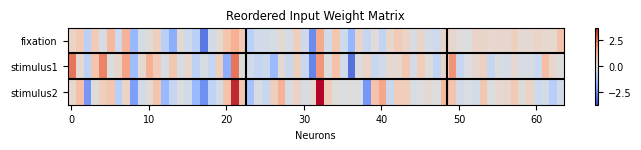

In [16]:
input_weight = model.lstm.input_layer.weight.detach().cpu().numpy()
print(input_weight.shape)
reordered_input_weight = input_weight[perm, :]
reordered_input_weight_transposed = reordered_input_weight.T
plt.figure(figsize=(8,1))
limit = np.max(np.abs(reordered_input_weight_transposed))
plt.imshow(reordered_input_weight_transposed, cmap='coolwarm', aspect='auto', vmin=-limit, vmax=limit)
plt.colorbar()
plt.vlines([n_neuron1 - 0.5, n_neuron1 + n_neuron2 - 0.5], -0.5, input_weight.shape[1]-0.5, color='black', linestyle='-')
plt.hlines([0.5, 1.5], -0.5, N-0.5, color='black', linestyle='-')
plt.title('Reordered Input Weight Matrix')
plt.xlabel('Neurons')
# plt.ylabel('Input Features')
plt.yticks(np.arange(input_weight.shape[1]), ['fixation', 'stimulus1', 'stimulus2'])
plt.show()

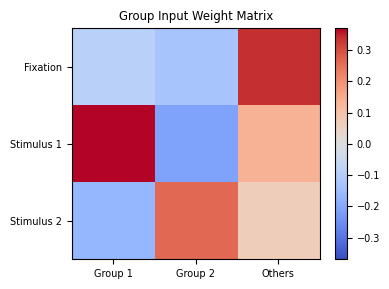

In [17]:
group_weight_input = np.zeros((3,3))
group_weight_input[0,0] = reordered_input_weight_transposed[0, :n_neuron1].mean()
group_weight_input[0,1] = reordered_input_weight_transposed[0, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight_input[0,2] = reordered_input_weight_transposed[0, n_neuron1+n_neuron2:].mean()
group_weight_input[1,0] = reordered_input_weight_transposed[1, :n_neuron1].mean()
group_weight_input[1,1] = reordered_input_weight_transposed[1, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight_input[1,2] = reordered_input_weight_transposed[1, n_neuron1+n_neuron2:].mean()
group_weight_input[2,0] = reordered_input_weight_transposed[2, :n_neuron1].mean()
group_weight_input[2,1] = reordered_input_weight_transposed[2, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight_input[2,2] = reordered_input_weight_transposed[2, n_neuron1+n_neuron2:].mean()
group_weight_input_normalized = group_weight_input / np.std(reordered_input_weight_transposed)
plt.figure(figsize=(4,3))
limit = np.max(np.abs(group_weight_input_normalized))
plt.imshow(group_weight_input_normalized, cmap='coolwarm', aspect='auto', vmin=-limit, vmax=limit)
plt.colorbar()
plt.title('Group Input Weight Matrix')
# plt.xlabel('Groups')
# plt.ylabel('Input Features')
plt.xticks([0, 1, 2], ['Group 1', 'Group 2', 'Others'])
plt.yticks([0, 1, 2], ['Fixation', 'Stimulus 1', 'Stimulus 2'])
plt.show()

(3, 64)


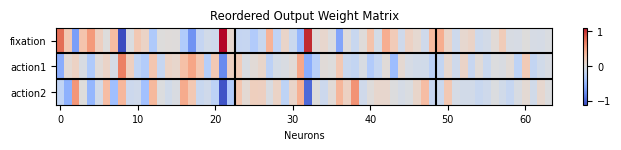

In [18]:
output_weight = model.lstm.output_layer.weight.detach().cpu().numpy()
print(output_weight.shape)
reordered_output_weight = output_weight[:, perm]
plt.figure(figsize=(8,1))
plt.imshow(reordered_output_weight, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.vlines([n_neuron1 - 0.5, n_neuron1 + n_neuron2 - 0.5], -0.5, output_weight.shape[0]-0.5, color='black', linestyle='-')
plt.hlines([0.5, 1.5], -0.5, N-0.5, color='black', linestyle='-')
plt.title('Reordered Output Weight Matrix')
plt.xlabel('Neurons')
# plt.ylabel('Output Actions')
plt.yticks(np.arange(output_weight.shape[0]), ['fixation', 'action1', 'action2'])
plt.show()

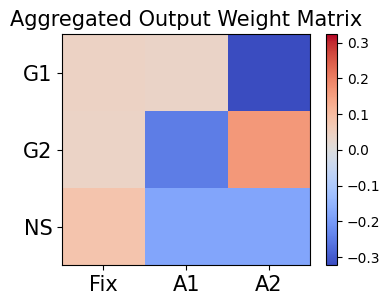

In [19]:
group_weight_output = np.zeros((3,3))
group_weight_output[0,0] = reordered_output_weight[0, :n_neuron1].mean()
group_weight_output[0,1] = reordered_output_weight[0, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight_output[0,2] = reordered_output_weight[0, n_neuron1+n_neuron2:].mean()
group_weight_output[1,0] = reordered_output_weight[1, :n_neuron1].mean()
group_weight_output[1,1] = reordered_output_weight[1, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight_output[1,2] = reordered_output_weight[1, n_neuron1+n_neuron2:].mean()
group_weight_output[2,0] = reordered_output_weight[2, :n_neuron1].mean()
group_weight_output[2,1] = reordered_output_weight[2, n_neuron1:n_neuron1+n_neuron2].mean()
group_weight_output[2,2] = reordered_output_weight[2, n_neuron1+n_neuron2:].mean()
group_weight_output_normalized = group_weight_output / np.std(reordered_output_weight)
plt.figure(figsize=(4,3))
limit = np.max(np.abs(group_weight_output_normalized))
plt.imshow(group_weight_output_normalized.T, cmap='coolwarm', aspect='auto', vmin=-limit, vmax=limit)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=fontsize-5)
plt.title('Aggregated Output Weight Matrix', fontsize=fontsize)
# plt.xlabel('Groups')
# plt.ylabel('Output Actions')
plt.xticks([0, 1, 2], ['Fix', 'A1', 'A2'], fontsize=fontsize)
plt.yticks([0, 1, 2], ['G1', 'G2', 'NS'], fontsize=fontsize)
plt.savefig('./output/pdm_aggregated_output_weight_matrix.png', dpi=400)
plt.show()

In [22]:
env.test_new_trial(1,100)

AttributeError: 'PerceptualDecisionMaking' object has no attribute 'test_new_trial'

Separating the sensory module and action module


In [20]:
model.eval()
perf = 0
cohs = np.linspace(0,15,10)
choices = np.arange(2)
num_trial = 200
trial_length = 22
hidden_ar = np.zeros((choices.shape[0], cohs.shape[0], num_trial, trial_length, 64))
action_ar = np.zeros((choices.shape[0], cohs.shape[0], num_trial), dtype=int)
for i in range(choices.shape[0]):
    for j in range(cohs.shape[0]):
        for k in range(num_trial):
            env.test_new_trial(coh=cohs[j], choice=i)
            ob, gt = env.ob, env.gt
            ob = ob[:, np.newaxis, :]

            inputs = torch.from_numpy(ob).type(torch.float).to(device)

            outputs, eimask_logit, hidden = model(inputs)
            action_pred = outputs.cpu().detach().numpy()
            action_pred = np.argmax(action_pred, axis=-1)
            action_ar[i, j, k] = action_pred[-1, 0]
            hidden_ar[i, j, k, :] = hidden[0][:,0].cpu().detach().numpy()


AttributeError: 'PerceptualDecisionMaking' object has no attribute 'test_new_trial'

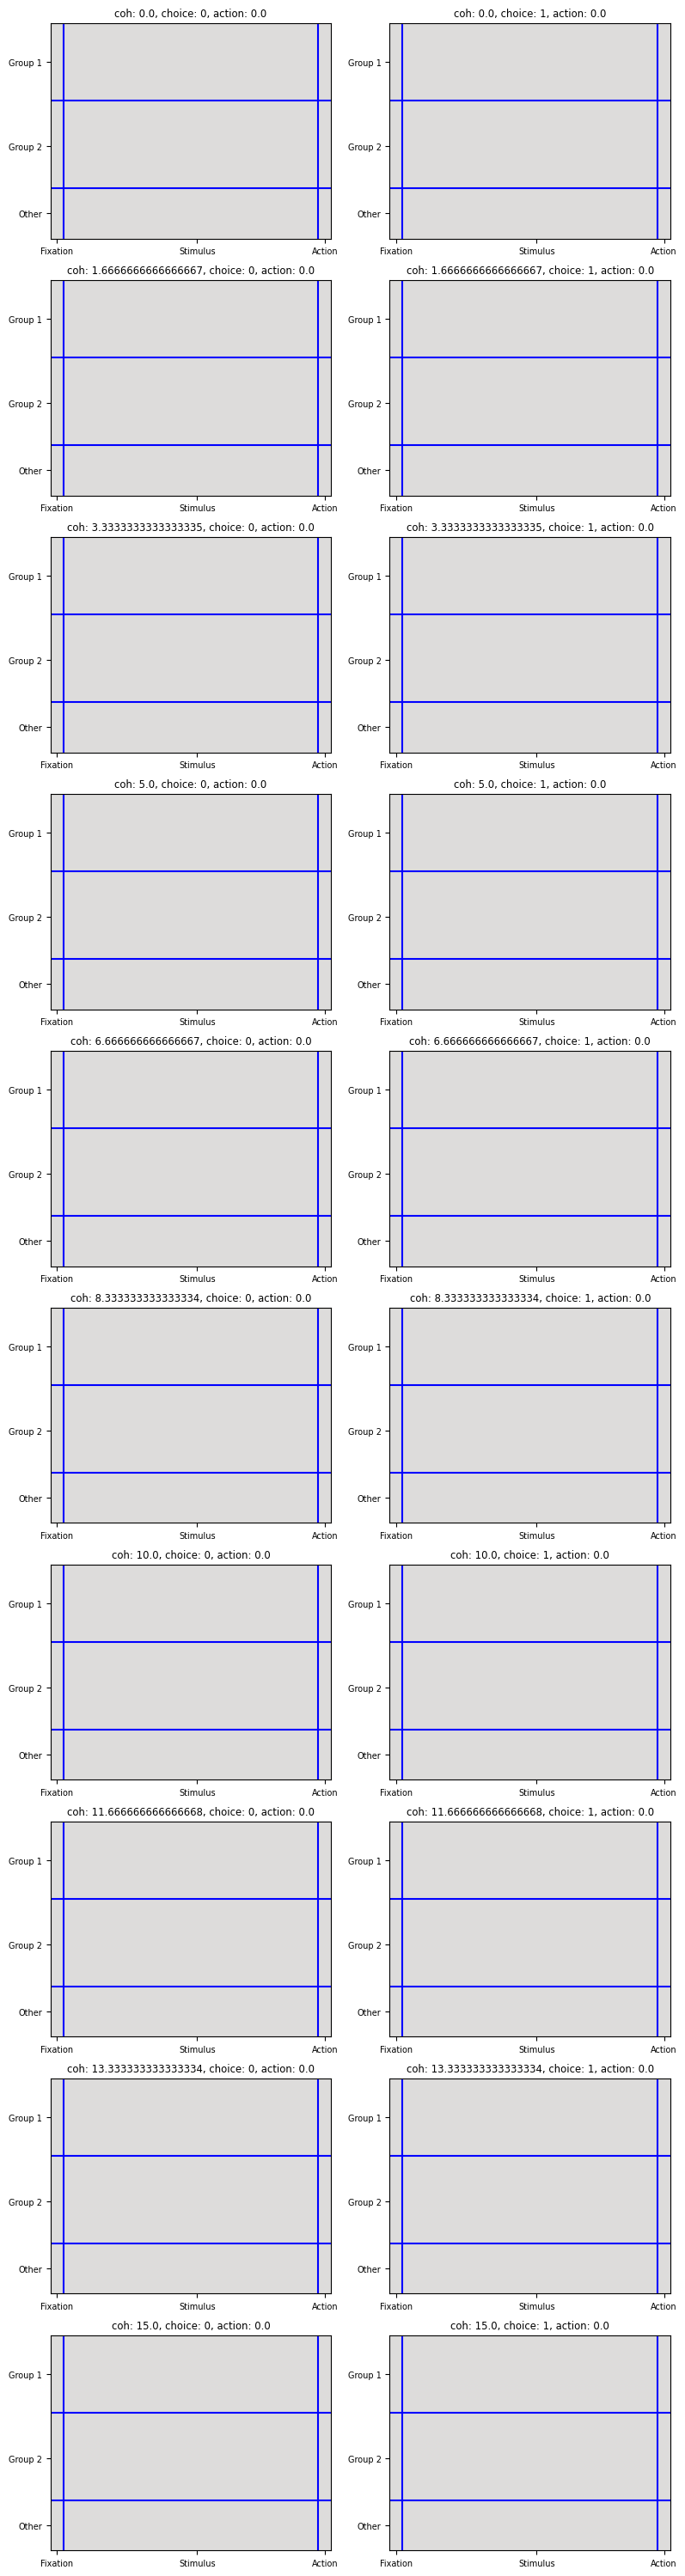

In [21]:
hidden_mean = hidden_ar.mean(axis=2)
action_mean = action_ar.mean(axis=2)
fig, ax = plt.subplots(cohs.shape[0], choices.shape[0], figsize=(8, 30))
for i in range(cohs.shape[0]):
    for j in range(choices.shape[0]):
        hidden_expectation_transposed = hidden_mean[j, i].T
        reordered_hidden = hidden_expectation_transposed[perm, :]
        ax[i, j].imshow(reordered_hidden, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
        ax[i, j].set_title(f'coh: {cohs[i]}, choice: {choices[j]}, action: {action_mean[j, i]}')
        # ax[i, j].set_xlabel('Time')
        # ax[i, j].set_ylabel('Neurons')
        ax[i, j].hlines([n_neuron1 - 0.5, n_neuron1 + n_neuron2 - 0.5], -0.5, trial_length-0.5, color='blue', linestyle='-')
        ax[i, j].vlines([0.5, trial_length - 1.5], -0.5, hidden_mean.shape[-1]-0.5, color='blue', linestyle='-')
        ax[i, j].set_xticks(ticks=[0,trial_length//2,trial_length-1], labels=['fixation', 'stimulus', 'action'])
        ax[i, j].set_xticklabels(['Fixation', 'Stimulus', 'Action'])
        ax[i, j].set_yticks(ticks=[n_neuron1//2, n_neuron1 + n_neuron2//2, n_neuron1 + n_neuron2 + n_neuron_other//2],
                           labels=['Group 1', 'Group 2', 'Other'])
plt.tight_layout()
plt.show()

In [47]:
stimulus = np.concatenate([-cohs[::-1], cohs])
print(stimulus)
left_trial_action = action_mean[0]
right_trial_action = action_mean[1]
response = np.concatenate([left_trial_action[::-1]-1, right_trial_action-1])
print(response)

[-15.         -13.33333333 -11.66666667 -10.          -8.33333333
  -6.66666667  -5.          -3.33333333  -1.66666667  -0.
   0.           1.66666667   3.33333333   5.           6.66666667
   8.33333333  10.          11.66666667  13.33333333  15.        ]
[0.    0.    0.    0.    0.    0.005 0.01  0.035 0.11  0.255 0.29  0.42
 0.63  0.805 0.95  0.985 0.99  0.995 1.    1.   ]


In [48]:
from scipy.optimize import curve_fit
def logistic(x, a, b):
    return 1 / (1 + np.exp(-(a * x + b)))
params, covariance = curve_fit(logistic, stimulus, response, p0=[1, 0])
fitted_a, fitted_b = params
fitted_value = logistic(stimulus, *params)

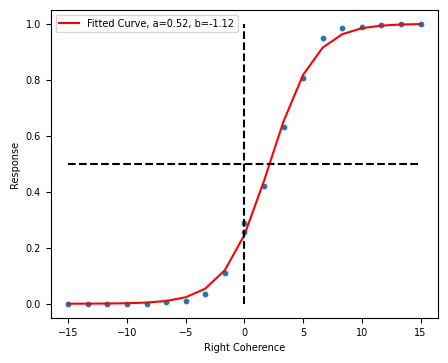

In [49]:
fig, ax = plt.subplots(1, 1, figsize=(5,4))
ax.plot(stimulus, fitted_value, color='red', label=f'Fitted Curve, a={fitted_a:.2f}, b={fitted_b:.2f}')
ax.scatter(stimulus, response, s=10)
ax.legend()
ax.vlines([0], 0, 1, color='black', linestyle='--')
ax.hlines(0.5, stimulus[0], stimulus[-1], color='black', linestyle='--')
ax.set_xlabel('Right Coherence')
ax.set_ylabel('Response')
plt.show()

In [28]:
stimulus_response = np.stack((stimulus, response),axis=0)
np.save('./output/stimulus_response_eisep_tanh.npy', stimulus_response)

In [29]:
eisep_sr = np.load('./output/stimulus_response_eisep_tanh.npy')
simple_sr = np.load('./output/stimulus_response_simpleRNN.npy')
stimulus = eisep_sr[0]
eisep_response = eisep_sr[1]
simple_response = simple_sr[1]
(a1, b1), cov_eisep = curve_fit(logistic, stimulus, eisep_response, p0=[1, 0])
(a2, b2), cov_simple = curve_fit(logistic, stimulus, simple_response, p0=[1, 0])
fitted_value_eisep = logistic(stimulus, *[a1, b1])
fitted_value_simple = logistic(stimulus, *[a2, b2])

In [30]:
from scipy import stats
t_a = (a1 - a2) / np.sqrt(cov_eisep[0, 0] + cov_simple[0, 0])
df = eisep_response.shape[0] - 2
p_value = 2 * (1 - stats.t.cdf(np.abs(t_a), df))
print(f't-statistic: {t_a}, p-value: {p_value}')

t-statistic: 0.6148031934275585, p-value: 0.5463788933814988


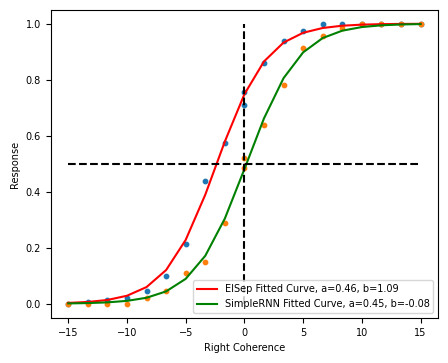

In [31]:
fig, ax = plt.subplots(1, 1, figsize=(5,4))
ax.scatter(stimulus, eisep_response, s=10)
ax.scatter(stimulus, simple_response, s=10)
ax.plot(stimulus, fitted_value_eisep, color='red', label=f'EISep Fitted Curve, a={a1:.2f}, b={b1:.2f}')
ax.plot(stimulus, fitted_value_simple, color='green', label=f'SimpleRNN Fitted Curve, a={a2:.2f}, b={b2:.2f}')
ax.legend()
ax.vlines([0], 0, 1, color='black', linestyle='--')
ax.hlines(0.5, stimulus[0], stimulus[-1], color='black', linestyle='--')
ax.set_xlabel('Right Coherence')
ax.set_ylabel('Response')
plt.show()